<a href="https://colab.research.google.com/github/Ariiiiii22/MetroCDMX_DFS-y-BFS/blob/main/RedesNeuronales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal

In [44]:
import pandas as pd
import numpy as np

In [45]:
df = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

In [46]:
df.head(5)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


# Operaciones fila

Transformaciones que usan solo la información de cada pasajero (su propia fila), por eso se pueden hacer antes de dividir los datos.

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8492 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [48]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [49]:
df.isna().sum()[df.isna().sum() > 0] / df.shape[0] * 100

,0
HomePlanet,2.312205
CryoSleep,2.496261
Cabin,2.289198
Destination,2.093639
Age,2.059128
VIP,2.335212
RoomService,2.082135
FoodCourt,2.105142
ShoppingMall,2.392730
Spa,2.105142


In [50]:
# Cabin tiene el formato deck/num/side -> la separamos en tres columnas
for data in [df, df_test]:
    data[["Deck", "CabinNum", "Side"]] = data["Cabin"].str.split("/", expand=True)
    data["CabinNum"] = pd.to_numeric(data["CabinNum"])

In [51]:
gastos = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

for data in [df, df_test]:
    # Si el pasajero gastó dinero, no estaba en criosueño
    gasto_conocido = data[gastos].sum(axis=1)
    data.loc[data["CryoSleep"].isna() & (gasto_conocido > 0), "CryoSleep"] = False
    # Si estaba en criosueño, está en su cabina: su gasto es 0
    data.loc[data["CryoSleep"] == True, gastos] = data.loc[data["CryoSleep"] == True, gastos].fillna(0)

In [52]:
for data in [df, df_test]:
    data["total_spend"] = data[gastos].sum(axis=1)   # sum ignora los NaN
    data["no_spend"] = data["total_spend"] == 0

In [53]:
for data in [df, df_test]:
    for column in gastos + ["total_spend"]:
        data[column] = np.log1p(data[column])

In [54]:
ids_test = df_test["PassengerId"]   # lo guardamos para el archivo de envío

for data in [df, df_test]:
    del data["Cabin"]
    del data["PassengerId"]
    del data["Name"]

In [55]:
df.head(5)

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Deck,CabinNum,Side,total_spend,no_spend
0,Europa,False,TRAPPIST-1e,39.0,False,0.000000,0.000000,0.000000,0.000000,0.000000,False,B,0.0,P,0.000000,True
1,Earth,False,TRAPPIST-1e,24.0,False,4.700480,2.302585,3.258097,6.309918,3.806662,True,F,0.0,S,6.602588,False
2,Europa,False,TRAPPIST-1e,58.0,True,3.784190,8.182280,0.000000,8.812248,3.912023,False,A,0.0,S,9.248021,False
3,Europa,False,TRAPPIST-1e,33.0,False,0.000000,7.157735,5.918894,8.110728,5.267858,False,A,0.0,S,8.551981,False
4,Earth,False,TRAPPIST-1e,16.0,False,5.717028,4.262680,5.023881,6.338594,1.098612,True,F,1.0,S,6.995766,False


# Operaciones con información global

In [56]:
X = df.drop("Transported", axis = 1)
y = df["Transported"].astype(int)

In [57]:
y.value_counts() / df.shape[0] * 100

,count
Transported,
1,50.362361
0,49.637639


In [58]:
from sklearn.model_selection import train_test_split

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify = y
)

In [60]:
X_train = X_train.reset_index(drop = True)
X_test = X_test.reset_index(drop = True)
X_sub = df_test.copy()   # datos de test.csv para el envío

In [61]:
y_train.value_counts() / X_train.shape[0] * 100

,count
Transported,
1,50.369762
0,49.630238


In [62]:
y_test.value_counts() / X_test.shape[0] * 100

,count
Transported,
1,50.345092
0,49.654908


In [63]:
for column in ["HomePlanet", "Destination", "Deck", "Side", "CryoSleep", "VIP"]:
    moda = X_train[column].mode().iloc[0]
    X_train[column] = X_train[column].fillna(moda)
    X_test[column] = X_test[column].fillna(moda)
    X_sub[column] = X_sub[column].fillna(moda)

/tmp/ipykernel_1130/1414177387.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[column] = X_train[column].fillna(moda)
/tmp/ipykernel_1130/1414177387.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[column] = X_test[column].fillna(moda)
/tmp/ipykernel_1130/1414177387.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
 

In [64]:
for column in ["Age", "CabinNum"] + gastos:
    media = X_train[column].mean()
    X_train[column] = X_train[column].fillna(media)
    X_test[column] = X_test[column].fillna(media)
    X_sub[column] = X_sub[column].fillna(media)

In [65]:
for data in [X_train, X_test, X_sub]:
    for column in ["CryoSleep", "VIP", "no_spend"]:
        data[column] = data[column].astype(int)

In [66]:
from sklearn.preprocessing import OneHotEncoder

In [67]:
for column in ["HomePlanet", "Destination", "Deck", "Side"]:
    encoder = OneHotEncoder(sparse_output=False, handle_unknown = "ignore")
    encoder.fit(X_train[[column]])
    nombres = list(map(lambda x: column + "_" + str(x), encoder.categories_[0]))
    X_train = pd.concat([
        X_train.drop(column, axis = 1),
        pd.DataFrame(encoder.transform(X_train[[column]]), columns = nombres)],
        axis = 1
    )
    X_test = pd.concat([
        X_test.drop(column, axis = 1),
        pd.DataFrame(encoder.transform(X_test[[column]]), columns = nombres)],
        axis = 1
    )
    X_sub = pd.concat([
        X_sub.drop(column, axis = 1),
        pd.DataFrame(encoder.transform(X_sub[[column]]), columns = nombres)],
        axis = 1
    )

In [68]:
X_train

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,CabinNum,total_spend,...,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_P,Side_S
0,1,28.0,0,0.000000,0.000000,0.0,0.000000,0.000000,591.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0,32.0,0,0.000000,7.675546,0.0,9.175335,6.756932,317.0,9.446913,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0,31.0,0,0.000000,7.592870,0.0,5.153292,3.970292,70.0,7.699842,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1,25.0,0,0.000000,0.000000,0.0,0.000000,0.000000,285.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,0,26.0,0,1.945910,6.591674,0.0,7.149917,7.018402,267.0,8.046870,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6080,0,62.0,1,0.000000,8.414939,0.0,4.454347,7.271009,119.0,8.705497,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6081,0,38.0,0,5.214936,5.318120,0.0,4.709530,5.926926,951.0,6.769642,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6082,1,28.0,0,0.000000,0.000000,0.0,0.000000,0.000000,452.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
6083,1,35.0,0,0.000000,0.000000,0.0,0.000000,0.000000,920.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [69]:
from sklearn.preprocessing import StandardScaler

In [70]:
numericas = ["Age", "CabinNum"] + gastos + ["total_spend"]
scaler = StandardScaler()
scaler.fit(X_train[numericas])

StandardScaler()

In [71]:
X_train[numericas] = scaler.transform(X_train[numericas])
X_test[numericas] = scaler.transform(X_test[numericas])
X_sub[numericas] = scaler.transform(X_sub[numericas])

In [72]:
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")
X_sub = X_sub.astype("float32")
y_train_nn = y_train.values.reshape(-1, 1).astype("float32")
y_test_nn = y_test.values.reshape(-1, 1).astype("float32")
X_train.shape

(6085, 27)

In [73]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units = 1, activation = "sigmoid")
])

model.compile(
    optimizer = "adam",
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=["accuracy", tf.keras.metrics.F1Score(threshold=0.5)]
)

In [74]:
historia_1 = model.fit(X_train, y_train_nn, epochs = 200, validation_data = (X_test, y_test_nn), verbose = 0)

In [75]:
model.evaluate(X_test, y_test_nn, return_dict = True)

82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7768 - f1_score: 0.7792 - loss: 0.4697


{'accuracy': 0.7768405079841614,
 'f1_score': array([0.77921087], dtype=float32),
 'loss': 0.469737708568573}

In [76]:
historia_2 = model_2.fit(X_train, y_train_nn, epochs = 100, batch_size = 64, validation_data = (X_test, y_test_nn), verbose = 0)

In [77]:
model_2.evaluate(X_test, y_test_nn, return_dict = True)

82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7952 - f1_score: 0.7917 - loss: 0.4319


{'accuracy': 0.7952454090118408,
 'f1_score': array([0.7917316], dtype=float32),
 'loss': 0.43194660544395447}

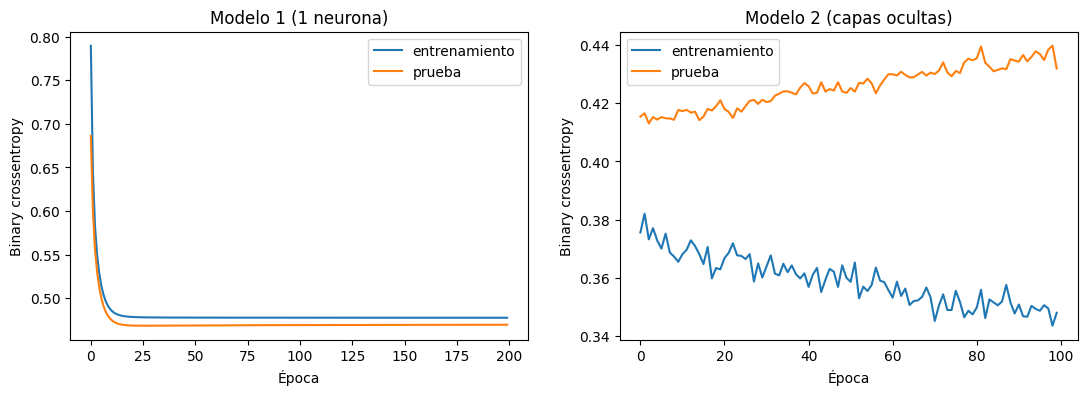

In [78]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, historia, titulo in [(axes[0], historia_1, "Modelo 1 (1 neurona)"), (axes[1], historia_2, "Modelo 2 (capas ocultas)")]:
    ax.plot(historia.history["loss"], label = "entrenamiento")
    ax.plot(historia.history["val_loss"], label = "prueba")
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel("Binary crossentropy")
    ax.legend()
plt.show()

In [79]:
from sklearn.metrics import accuracy_score, f1_score

for nombre, m in [("Modelo 1", model), ("Modelo 2", model_2)]:
    pred = m.predict(X_test, verbose = 0) > 0.5
    print(f"{nombre}: accuracy = {accuracy_score(y_test, pred):.4f}   F1 = {f1_score(y_test, pred):.4f}")

Modelo 1: accuracy = 0.7768   F1 = 0.7792
Modelo 2: accuracy = 0.7952   F1 = 0.7917


In [80]:
y_predict = model_2.predict(X_test) > 0.5

82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 895us/step


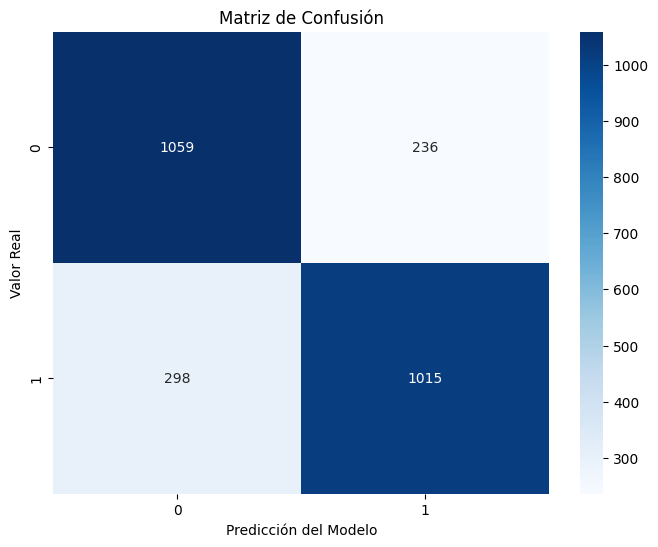

In [81]:
import seaborn as sns

matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predict)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

In [82]:
submission = pd.DataFrame({
    "PassengerId": ids_test,
    "Transported": (model_2.predict(X_sub, verbose = 0) > 0.5).ravel()
})
submission.to_csv("submission.csv", index = False)
submission.head()

,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
